cells: 9   queen edges: 20   (rook would only give 12)
simplices: 9 vertices + 20 edges + 16 triangles = 45

first simplices in filtration order (value, simplex):
  1:{0}  1.5:{8}  2.5:{3}  2.5:{0,3}  3:{1}  3:{0,1}  3:{1,3}  3:{0,1,3}  3.5:{7}  3.5:{3,7}  3.5:{7,8}  4:{5}  4:{1,5}  4:{5,7}  ...

persistence intervals found by the reduction:
  H0: [1, never)   born when vertex {0} enters
  H0: [1.5, 3.5)   born when vertex {8} enters, dies when edge {7,8} enters
  H1: [4, 9)   born when edge {5,7} enters, dies when triangle {4,5,7} enters
        the loop it records: {0,3}, {0,1}, {3,7}, {1,5}, {5,7}
        (one valid loop around the hole; others differ by filled triangles)
  (ignored 4 fake H2 classes created by stopping at triangles)
GUDHI H0: [(np.float64(1.0), np.float64(inf)), (np.float64(1.5), np.float64(3.5))]   matches my reduction: True
GUDHI H1: [(np.float64(4.0), np.float64(9.0))]   matches my reduction: True


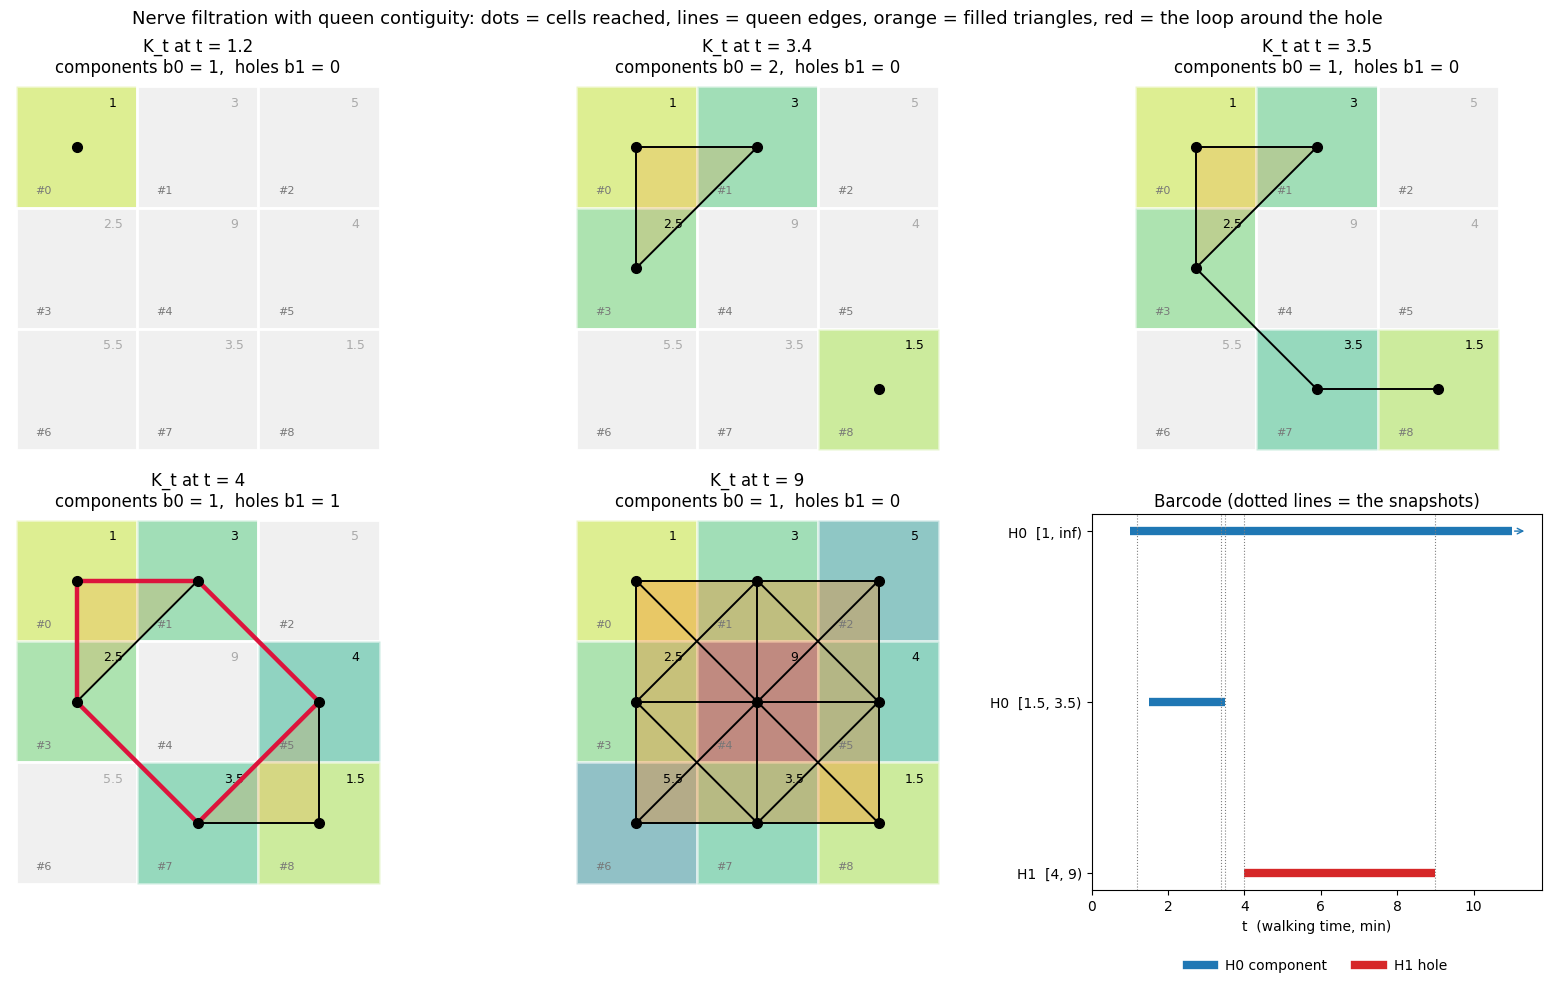

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.lines import Line2D
from shapely.geometry import box

# ==================================================================
# 1. A tiny "tessellation": 3 x 3 square cells, one value per cell.
#    Think of the value as walking time to the nearest hospital.
#    The centre is far away (9), ringed by cells that are all closer.
# ==================================================================
value_grid = np.array([[1.0, 3.0, 5.0],
                       [2.5, 9.0, 4.0],
                       [5.5, 3.5, 1.5]])
n_rows, n_cols = value_grid.shape
cells = [box(c, n_rows - 1 - r, c + 1, n_rows - r) for r in range(n_rows) for c in range(n_cols)]
f = value_grid.ravel()                       # f[i] = value of cell i  (ids run row by row)
n = len(cells)
centroid = np.array([[p.centroid.x, p.centroid.y] for p in cells])
label = lambda s: "{" + ",".join(map(str, s)) + "}"
kind = lambda s: ("vertex", "edge", "triangle")[len(s) - 1]

# ==================================================================
# 2. Queen contiguity: two cells are neighbours if the CLOSED cells
#    intersect, i.e. they share a border OR just a corner point.
# ==================================================================
queen_edges = [(i, j) for i, j in itertools.combinations(range(n), 2) if cells[i].intersects(cells[j])]
rook_edges = [(i, j) for i, j in queen_edges if cells[i].intersection(cells[j]).length > 0]
print(f"cells: {n}   queen edges: {len(queen_edges)}   (rook would only give {len(rook_edges)})")

# ==================================================================
# 3. The nerve as a simplicial complex (the clique / flag complex)
#      vertices  = cells
#      edges     = queen-adjacent pairs
#      triangles = three cells that are pairwise adjacent
#    A simplex appears once ALL its cells are reached: value = max of f.
# ==================================================================
neighbours = {i: set() for i in range(n)}
for i, j in queen_edges:
    neighbours[i].add(j); neighbours[j].add(i)
triangles = [(i, j, k) for (i, j) in queen_edges for k in sorted(neighbours[i] & neighbours[j]) if k > j]
simplices = [(i,) for i in range(n)] + queen_edges + triangles
filt = {s: max(f[v] for v in s) for s in simplices}
print(f"simplices: {n} vertices + {len(queen_edges)} edges + {len(triangles)} triangles = {len(simplices)}")

# Order of insertion: by filtration value, faces always before the simplices they bound
order = sorted(simplices, key=lambda s: (filt[s], len(s), s))
position = {s: p for p, s in enumerate(order)}
print("\nfirst simplices in filtration order (value, simplex):")
print("  " + "  ".join(f"{filt[s]:g}:{label(s)}" for s in order[:14]) + "  ...")

# ==================================================================
# 4. Homology by hand: reduce the boundary matrix over Z/2.
#    Column j = the boundary of simplex j, stored as the set of rows
#    (faces) it contains. Adding two columns mod 2 = symmetric difference.
#    We keep adding earlier columns until every column has a unique
#    "lowest" row. Then:  low(j) = i  means  simplex j KILLS the class
#    that simplex i created.  Unpaired simplices never die (essential).
# ==================================================================
columns = [set() if len(s) == 1 else {position[s[:k] + s[k + 1:]] for k in range(len(s))} for s in order]
pivot_owner, pairs = {}, []
for j, col in enumerate(columns):
    while col and max(col) in pivot_owner:
        col ^= columns[pivot_owner[max(col)]]            # add the earlier column (mod 2)
    if col:
        pivot_owner[max(col)] = j
        pairs.append((max(col), j))
paired = {i for pair in pairs for i in pair}
essential = [i for i in range(len(order)) if not columns[i] and i not in paired]

intervals = []        # (dimension, birth value, death value, birth simplex, death simplex, cycle)
for i, j in pairs:
    b, d = filt[order[i]], filt[order[j]]
    if d > b:         # equal values = born and killed at the same moment: no persistence
        cycle = [order[r] for r in sorted(columns[j])] if len(order[i]) == 2 else None
        intervals.append((len(order[i]) - 1, b, d, order[i], order[j], cycle))
for i in essential:
    intervals.append((len(order[i]) - 1, filt[order[i]], np.inf, order[i], None, None))
intervals.sort(key=lambda t: (t[0], t[1]))

# We stopped at triangles, so hollow tetrahedra show up as fake 2-dimensional classes.
# They are an artefact of truncating the complex: only H0 and H1 are meaningful here.
n_fake = sum(1 for iv in intervals if iv[0] >= 2)
intervals = [iv for iv in intervals if iv[0] <= 1]

print("\npersistence intervals found by the reduction:")
for dim, b, d, sb, sd, cycle in intervals:
    death = "never" if sd is None else f"{d:g}"
    print(f"  H{dim}: [{b:g}, {death})   born when {kind(sb)} {label(sb)} enters"
          + ("" if sd is None else f", dies when {kind(sd)} {label(sd)} enters"))
    if cycle:
        print(f"        the loop it records: {', '.join(label(e) for e in cycle)}")
        print("        (one valid loop around the hole; others differ by filled triangles)")
print(f"  (ignored {n_fake} fake H2 classes created by stopping at triangles)")

# Cross-check with GUDHI (same complex, same values)
try:
    import gudhi
    st = gudhi.SimplexTree()
    for s in simplices:
        st.insert(list(s), filtration=float(filt[s]))
    st.compute_persistence(homology_coeff_field=2, min_persistence=0.0)
    for dim in (0, 1):
        g = sorted(map(tuple, np.round(np.asarray(st.persistence_intervals_in_dimension(dim)).reshape(-1, 2), 6)))
        mine = sorted((round(b, 6), round(d, 6)) for dm, b, d, *_ in intervals if dm == dim)
        print(f"GUDHI H{dim}: {g}   matches my reduction: {g == mine}")
except ImportError:
    print("(install gudhi to cross-check:  pip install gudhi)")

# ==================================================================
# 5. Pictures: the complex K_t at several times, and the barcode
# ==================================================================
def betti(dim, t):
    return sum(1 for dm, b, d, *_ in intervals if dm == dim and b <= t < d)

snap_times = [1.2, 3.4, 3.5, 4.0, 9.0]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
cmap = plt.get_cmap("viridis_r")
for ax, t in zip(axes.ravel(), snap_times):
    for i, poly in enumerate(cells):
        reached = f[i] <= t
        ax.add_patch(MplPolygon(np.array(poly.exterior.coords), closed=True,
                                fc=cmap(f[i] / 10) if reached else "#f0f0f0", ec="white", lw=2, alpha=0.5 if reached else 1))
        ax.text(*centroid[i] + [0.30, 0.34], f"{f[i]:g}", fontsize=9, ha="center", color="black" if reached else "#aaaaaa")
        ax.text(*centroid[i] + [-0.34, -0.38], f"#{i}", fontsize=8, ha="left", color="#777777")
    for tri in triangles:
        if filt[tri] <= t:
            ax.add_patch(MplPolygon(centroid[list(tri)], closed=True, fc="tab:orange", alpha=0.18, ec="none"))
    loops = [c for dm, b, d, _, _, c in intervals if dm == 1 and c and b <= t < d]
    loop_edges = {e for c in loops for e in c}
    for e in queen_edges:
        if filt[e] <= t:
            ax.plot(*centroid[list(e)].T, color="crimson" if e in loop_edges else "k",
                    lw=3.2 if e in loop_edges else 1.4, zorder=3)
    for i in range(n):
        if f[i] <= t:
            ax.plot(*centroid[i], "o", color="k", ms=7, zorder=4)
    ax.set_xlim(-0.05, 3.05); ax.set_ylim(-0.05, 3.05); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"K_t at t = {t:g}\ncomponents b0 = {betti(0, t)},  holes b1 = {betti(1, t)}", fontsize=12)

ax = axes.ravel()[5]
colours = {0: "tab:blue", 1: "tab:red"}
end = 11
for y, (dim, b, d, *_) in enumerate(reversed(intervals)):
    ax.plot([b, min(d, end)], [y, y], lw=6, color=colours[dim], solid_capstyle="butt")
    if np.isinf(d):
        ax.annotate("", xy=(end + 0.4, y), xytext=(end, y), arrowprops=dict(arrowstyle="->", color=colours[dim]))
for t in snap_times:
    ax.axvline(t, color="grey", lw=0.8, ls=":")
ax.set_yticks(range(len(intervals)))
ax.set_yticklabels([f"H{dm}  [{b:g}, {'inf' if np.isinf(d) else format(d, 'g')})" for dm, b, d, *_ in reversed(intervals)])
ax.set_xlim(0, end + 0.8); ax.set_xlabel("t  (walking time, min)")
ax.set_title("Barcode (dotted lines = the snapshots)", fontsize=12)
ax.legend(handles=[Line2D([0], [0], color="tab:blue", lw=6, label="H0 component"),
                   Line2D([0], [0], color="tab:red", lw=6, label="H1 hole")],
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.suptitle("Nerve filtration with queen contiguity: dots = cells reached, lines = queen edges, "
             "orange = filled triangles, red = the loop around the hole", fontsize=13)
plt.tight_layout()
plt.show()

In [2]:
import itertools
import numpy as np
from shapely.geometry import box

# 1. Valores originales
value_grid = np.array([
    [1.0, 3.0, 5.0],
    [2.5, 9.0, 4.0],
    [5.5, 3.5, 1.5]
])

n_rows, n_cols = value_grid.shape

# 2. Construir las 9 celdas
cells = [
    box(c, n_rows - 1 - r, c + 1, n_rows - r)
    for r in range(n_rows)
    for c in range(n_cols)
]

# 3. Construir el nervio geométrico completo
nerve = []

for k in range(1, len(cells) + 1):
    for sigma in itertools.combinations(range(len(cells)), k):

        intersection = cells[sigma[0]]

        for i in sigma[1:]:
            intersection = intersection.intersection(cells[i])

            if intersection.is_empty:
                break

        if not intersection.is_empty:
            nerve.append(sigma)

# 4. Clasificar los simplex por dimensión
vertices = [s for s in nerve if len(s) == 1]
edges = [s for s in nerve if len(s) == 2]
triangles = [s for s in nerve if len(s) == 3]
tetrahedra = [s for s in nerve if len(s) == 4]

print("Vértices:", len(vertices))
print("Aristas:", len(edges))
print("Triángulos:", len(triangles))
print("Tetraedros:", len(tetrahedra))

Vértices: 9
Aristas: 20
Triángulos: 16
Tetraedros: 4
